# Halpha equivalent width in SF and NSF regions by infall stage - 2026-10-27

Adapted from `20261027_check_intrinsic_NII6583_dispersion_SF_NSF_by_stage.ipynb`.
Compare finite positive `PROXY_EWHA` values in Angstrom across Pre-peak,
Close-to-peak and Post-peak stages, with no global stellar-mass selection.
Nonpositive and nonfinite EW values are excluded from EW statistics only.
No NII dispersion or NII flux-S/N requirement is applied.

Preserve inclination <80 degrees, finite SNR_POSTFIT >25, finite local stellar
surface density and gas BIN_ID, and MASK==0. SF requires finite HII SFR,
EW(Halpha)>6 Angstrom and finite positive intrinsic Halpha sigma<45 km/s.
ND fails either source Balmer detection threshold; NSF is the remaining usable
population. ND is excluded from EW samples. The EW(Halpha)>6 SF definition
directly truncates the SF EW distribution; SF/NSF EW differences are therefore
partly linked to classification and are not an independent diagnostic.

Profiles retain shared 0.25-wide bins across the full finite coordinate ranges,
with displayed local log Sigma_star=6-11 and R/Re=0-2. Each product/category/bin
requires >=50 common usable SF+NSF+ND spaxels and >=20 finite positive
EW values in the category. Categories may have different support.
Equal-galaxy profiles average supported product mean EWs; pooled-spaxel
profiles divide their summed EWs by their spaxel counts. Neither estimator
weights by line flux.

Bands show the 16th-84th percentiles of 10,000 whole-product bootstrap draws
within each stage, shared across categories and coordinate bins within each
estimator. Single-product bins retain central values with blank uncertainty
bands. NGC4567_8 retains the minimum component R/Re geometry and counts as
one product/weight/bootstrap unit. These bands describe product sampling;
individual EW measurement uncertainties are not propagated.

Retain the full-sample, inner/outer and spatially stratified distributions,
with both estimators and the source normalization conventions documented below.
FITS inputs and the source notebook are read only. Optional PNG/PDF export is
disabled by default; the new notebook has its own output directory.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8'
OUTPUT_DIR = PROJECT_ROOT / '20261027_EWHa_SF_NSF_by_stage_assets'
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
SNR_POSTFIT_MIN = 25.0
INCLINATION_MAX = 80.0
EW_MIN, SIGMA_MAX = 6.0, 45.0
PROFILE_X_LIMITS = {'log_sigma_star': (6.0, 11.0), 'radius_re': (0.0, 2.0)}
PROFILE_BIN_WIDTH = 0.25
FRACTION_EDGES = {}
FRACTION_MIN_USABLE = 50
EWHA_MIN_PIXELS = 20
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
STAGE_LABELS = {1: 'Pre-peak', 2: 'Close-to-peak', 3: 'Post-peak'}
STAGE_COLORS = {1: '#2166ac', 2: '#1a9850', 3: '#d73027'}
CATEGORIES = ('SF', 'NSF')
# Histogram probabilities per bin, not probability density per unit EW(Halpha).
EWHA_HIST_EDGES = np.arange(0.0, 300.0 + 0.5, 1.0)
EWHA_HIST_X_LIMITS = (0.0, 50.0)  # display only; tails remain in denominators
EWHA_HIST_LOG_LIMITS = (-5.0, 0.0)
SAVE_FIGURES = False
mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 11, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

def save_figure(fig, stem):
    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        for suffix in ('png', 'pdf'):
            fig.savefig(OUTPUT_DIR / f'{stem}.{suffix}', dpi=200, bbox_inches='tight')

In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    # Minimum elliptical R/Re over the physical components of one product.
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, component in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(
            ra, dec, component.center_ra_deg, component.center_dec_deg
        )
        pa = np.deg2rad(float(component.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        component_radius = np.sqrt(
            (major / float(component.a_re_arcsec)) ** 2
            + (minor / float(component.b_re_arcsec)) ** 2
        )
        radius = np.minimum(radius, component_radius)
    radius[~np.isfinite(radius)] = np.nan
    return radius

# Authoritative stage/geometry join; combined components must agree in stage.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip():int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int),geometry.mauve_infall_stage.astype(int))


def ewha_histogram_parts(values, radii, edges):
    """Count all/inner/outer samples with an auditable finite histogram window."""
    values, radii = np.asarray(values), np.asarray(radii)
    assert values.shape == radii.shape
    assert np.isfinite(values).all() and (values > 0).all()
    assert np.isfinite(radii).all()
    selections = {'all': np.ones(values.shape, dtype=bool),
                  'inner': radii < 1.0, 'outer': radii >= 1.0}
    result = {}
    for region, select in selections.items():
        v = values[select]
        hist = np.histogram(v, bins=edges)[0]
        below, above = int((v < edges[0]).sum()), int((v > edges[-1]).sum())
        assert int(hist.sum()) + below + above == len(v)
        result[region] = dict(hist=hist, N_region=len(v), N_below_grid=below, N_above_grid=above)
    assert np.array_equal(result['all']['hist'], result['inner']['hist'] + result['outer']['hist'])
    assert result['all']['N_region'] == result['inner']['N_region'] + result['outer']['N_region']
    return result



# Separate one-dimensional splits, not a joint 4x4 mass-radius selection.
STRATUM_LABELS = {
    'log_sigma_star': (r'$\log\Sigma_*<7.5$', r'$7.5\leq\log\Sigma_*<8.5$',
                      r'$8.5\leq\log\Sigma_*\leq9.5$', r'$\log\Sigma_*>9.5$'),
    'radius_re': (r'$0\leq R/R_e<0.5$', r'$0.5\leq R/R_e<1$',
                  r'$1\leq R/R_e\leq1.5$', r'$R/R_e>1.5$'),
}

def spatial_stratum_masks(variable, values):
    values = np.asarray(values)
    assert np.isfinite(values).all()
    if variable == 'log_sigma_star':
        masks = (values < 7.5, (values >= 7.5) & (values < 8.5),
                 (values >= 8.5) & (values <= 9.5), values > 9.5)
    elif variable == 'radius_re':
        assert (values >= 0).all()
        masks = ((values >= 0) & (values < 0.5), (values >= 0.5) & (values < 1.0),
                 (values >= 1.0) & (values <= 1.5), values > 1.5)
    else:
        raise ValueError(variable)
    assert np.all(np.sum(masks, axis=0) == 1), 'Strata must partition the selected sample'
    return masks

## Load the common selection and EW(Halpha) values
Preserve classification and geometry; evaluate finite positive EW(Halpha) support separately in SF and NSF.


In [3]:
product_meta = {}
for galid, components in geometry.groupby('notebook_product_id'):
    assert components.stage_code.nunique()==1, f'{galid}: inconsistent component stages'
    incl = components.inclination_deg.to_numpy(float)
    product_meta[galid] = dict(stage=int(components.stage_code.iloc[0]),
        inclination=float(incl.max()),
        inclination_ok=bool(np.isfinite(incl).all() and (incl<INCLINATION_MAX).all()))
inventory_rows, count_rows, ewha_rows, provenance_rows, histogram_rows, stratified_histogram_rows = [], [], [], [], [], []
for folder in sorted(p for p in DATA_ROOT.iterdir() if p.is_dir() and not p.name.endswith('_logs')):
    gal = folder.name  # preserves combined IDs such as NGC4567_8
    paths = {
        'mass': first_existing(folder, [f'{gal}_spatial_binning_maps_further.fits', f'{gal}_SPATIAL_BINNING_maps_further.fits']),
        'gas': first_existing(folder, [f'{gal}_gas_bin_maps_further.fits', f'{gal}_gas_BIN_maps_further.fits']),
        'ew': first_existing(folder, [f'{gal}_proxy_EW_maps_further.fits', f'{gal}_proxy_EW_maps.fits']),
        'sfh': first_existing(folder, [f'{gal}_sfh_maps.fits']),
        'mask': first_existing(folder, [f'{gal}_mask.fits']),
    }
    if gal not in product_meta:
        raise KeyError(f'{gal}: no authoritative inclination/stage metadata')
    meta = product_meta[gal]
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))

inventory = pd.DataFrame(inventory_rows)
# Shared bins span every finite mass/radius value in included product maps.
# No mass or radius selection is applied to the ewha profiles.
profile_bounds = {key: [np.inf, -np.inf] for key in ('log_sigma_star', 'radius_re')}
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    mass_for_edges, header_for_edges = read_map(record.mass, 'LOGMASS_SURFACE_DENSITY')
    radius_for_edges = calculate_deprojected_radius(
        mass_for_edges.shape, header_for_edges,
        geometry.loc[geometry.notebook_product_id.eq(record.galaxy)])
    for variable, values in (('log_sigma_star', mass_for_edges), ('radius_re', radius_for_edges)):
        finite = values[np.isfinite(values)]
        if finite.size:
            profile_bounds[variable][0] = min(profile_bounds[variable][0], float(finite.min()))
            profile_bounds[variable][1] = max(profile_bounds[variable][1], float(finite.max()))
for variable, (lower, upper) in profile_bounds.items():
    if not np.isfinite([lower, upper]).all():
        raise ValueError(f'{variable}: no finite profile coordinates')
    first_bin = int(np.floor(lower / PROFILE_BIN_WIDTH))
    # Final edge is strictly above the maximum, including exact edge values.
    last_bin = int(np.floor(upper / PROFILE_BIN_WIDTH)) + 1
    FRACTION_EDGES[variable] = np.arange(first_bin, last_bin + 1) * PROFILE_BIN_WIDTH
del mass_for_edges, radius_for_edges
print('Full-range profile bin edges:', {key: (edges[0], edges[-1]) for key, edges in FRACTION_EDGES.items()})

for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    meta = product_meta[gal]
    paths = {key: Path(getattr(record, key)) for key in ('mass', 'gas', 'ew', 'sfh', 'mask')}
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'LOGSFR_SURFACE_DENSITY_UPPER',
            'LOGSFR_SURFACE_DENSITY', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    # Mandatory first-stage usability gate: only then define SF, ND, or remaining NSF.
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0)
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    radius_re = calculate_deprojected_radius(mass.shape,mass_hdr,geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(radius_re[valid]).all(), f'{gal}: nonfinite R/Re in the common usable mask'
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    measurable = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        measurable &= good
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    # Preserve the source Halpha-based SF/ND/NSF classification.
    ha_sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    ha_sigma = np.sqrt(np.where(np.isfinite(ha_sigma2) & (ha_sigma2 > 0), ha_sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(ha_sigma) & (ha_sigma < SIGMA_MAX)
    nd = valid & ~balmer
    nd_upper = arrays['LOGSFR_SURFACE_DENSITY_UPPER']
    assert np.isfinite(nd_upper[nd]).all(), f'{gal}: missing ND SFR upper limits'
    assert np.allclose(nd_upper[nd], arrays['LOGSFR_SURFACE_DENSITY'][nd]), f'{gal}: ND SFR map mismatch'
    assert not np.any(sf & nd), f'{gal}: SF overlaps Balmer ND'
    assert np.all(snr_postfit[sf | nd] > 25.0), f'{gal}: category bypassed strict SNR cut'
    excluded = valid & ~sf & ~nd
    assert int(valid.sum()) == int(sf.sum()+nd.sum()+excluded.sum())
    nsf = excluded
    nsf_upper = arrays['LOGSFR_SURFACE_DENSITY']
    assert np.isfinite(nsf_upper[nsf]).all(), f'{gal}: missing NSF SFR upper-limit proxy'
    assert np.all(snr_postfit[nsf] > 25.0), f'{gal}: NSF bypassed strict SNR cut'
    assert np.array_equal(sf.astype(int)+nd.astype(int)+nsf.astype(int), valid.astype(int))



    # Analyse the same proxy EW map used by the unchanged SF classification.
    ewha = ew
    ewha_ok = np.isfinite(ewha) & (ewha > 0)
    count = dict(galaxy=gal, stage=meta['stage'], inclination=meta['inclination'],
                 usable=int(valid.sum()), SF=int(sf.sum()), ND=int(nd.sum()), NSF=int(nsf.sum()))
    provenance_rows.append(dict(galaxy=gal, CUT_SN=sn_cut, NOISE=floor,
        DUSTLAW=hdr.get('DUSTLAW', 'not recorded'), gas_path=str(paths['gas'])))
    for category, category_mask in (('SF', sf), ('NSF', nsf)):
        selected = category_mask & ewha_ok
        count['N_ewha_' + category] = int(selected.sum())
        parts = ewha_histogram_parts(ewha[selected], radius_re[selected], EWHA_HIST_EDGES)
        for region, part in parts.items():
            histogram_rows.append(dict(galaxy=gal, stage=meta['stage'], category=category,
                region=region, N_total=int(selected.sum()),
                N_outside_display=int(((ewha[selected] < min(EWHA_HIST_X_LIMITS))
                    | (ewha[selected] > max(EWHA_HIST_X_LIMITS))).sum()), **part))

        for split_variable, coordinates in (('log_sigma_star', mass), ('radius_re', radius_re)):
            stratum_masks = spatial_stratum_masks(split_variable, coordinates[selected])
            selected_ewhas = ewha[selected]
            for stratum, stratum_mask in enumerate(stratum_masks):
                v = selected_ewhas[stratum_mask]
                hist = np.histogram(v, bins=EWHA_HIST_EDGES)[0]
                below = int((v < EWHA_HIST_EDGES[0]).sum())
                above = int((v > EWHA_HIST_EDGES[-1]).sum())
                assert hist.sum() + below + above == len(v)
                stratified_histogram_rows.append(dict(galaxy=gal, stage=meta['stage'], category=category,
                    variable=split_variable, stratum=stratum, hist=hist, N_total=len(v),
                    N_parent=int(selected.sum()), N_below_grid=below, N_above_grid=above,
                    N_outside_display=int(((v < min(EWHA_HIST_X_LIMITS))
                                          | (v > max(EWHA_HIST_X_LIMITS))).sum())))
        for variable, values in (('log_sigma_star', mass), ('radius_re', radius_re)):
            edges = FRACTION_EDGES[variable]
            n_valid, _ = np.histogram(values[valid], bins=edges)
            n_category, _ = np.histogram(values[category_mask], bins=edges)
            n_ewha, _ = np.histogram(values[selected], bins=edges)
            total = np.histogram(values[selected], bins=edges, weights=ewha[selected])[0]
            assert n_ewha.sum() == selected.sum()
            assert np.all(n_ewha <= n_category) and np.all(n_category <= n_valid)
            for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
                ewha_rows.append(dict(galaxy=gal, stage=meta['stage'], category=category,
                    variable=variable, left=lo, right=hi, center=(lo + hi) / 2,
                    N_valid=int(n_valid[j]), N_category=int(n_category[j]), N_ewha=int(n_ewha[j]),
                    sum_primary=float(total[j]),
                    mean_primary=float(total[j] / n_ewha[j]) if n_ewha[j] else np.nan,
                    supported=bool(n_valid[j] >= FRACTION_MIN_USABLE and n_ewha[j] >= EWHA_MIN_PIXELS)))
    count_rows.append(count)
    print(f'{gal}: {count["N_ewha_SF"]:,} SF and {count["N_ewha_NSF"]:,} NSF finite positive EW(Halpha) values', flush=True)

counts = pd.DataFrame(count_rows)
ewha_by_galaxy = pd.DataFrame(ewha_rows)
provenance = pd.DataFrame(provenance_rows)
assert len(counts), 'No complete included products'
assert (counts.usable == counts.SF + counts.ND + counts.NSF).all()
assert counts.inclination.lt(INCLINATION_MAX).all()
assert (counts.N_ewha_SF <= counts.SF).all() and (counts.N_ewha_NSF <= counts.NSF).all()
display(inventory[['galaxy', 'stage', 'inclination', 'status']])
display(counts)
display(provenance)
display(counts.groupby('stage')[['usable', 'SF', 'ND', 'NSF', 'N_ewha_SF', 'N_ewha_NSF']].sum().rename(index=STAGE_LABELS))
print('Independent products by stage:', counts.groupby('stage').size().rename(index=STAGE_LABELS).to_dict())
ewha_histograms_by_galaxy = pd.DataFrame(histogram_rows)

stratified_histograms_by_galaxy = pd.DataFrame(stratified_histogram_rows)

Full-range profile bin edges: {'log_sigma_star': (np.float64(5.75), np.float64(11.25)), 'radius_re': (np.float64(0.0), np.float64(12.25))}
IC3392: 13,888 SF and 9,123 NSF finite positive EW(Halpha) values
NGC4064: 3,273 SF and 33,921 NSF finite positive EW(Halpha) values
NGC4189: 80,671 SF and 34,012 NSF finite positive EW(Halpha) values
NGC4254: 466,023 SF and 163,358 NSF finite positive EW(Halpha) values
NGC4293: 471 SF and 63,400 NSF finite positive EW(Halpha) values
NGC4294: 67,512 SF and 51,426 NSF finite positive EW(Halpha) values
NGC4298: 138,402 SF and 43,104 NSF finite positive EW(Halpha) values
NGC4321: 375,302 SF and 329,655 NSF finite positive EW(Halpha) values
NGC4351: 29,731 SF and 16,682 NSF finite positive EW(Halpha) values
NGC4380: 56,075 SF and 51,190 NSF finite positive EW(Halpha) values
NGC4383: 14,521 SF and 37,028 NSF finite positive EW(Halpha) values
NGC4394: 30,430 SF and 45,294 NSF finite positive EW(Halpha) values
NGC4405: 13,569 SF and 11,391 NSF finite posit

,galaxy,stage,inclination,status
0,IC3392,3,68.0,included
1,NGC4064,3,70.0,included
2,NGC4189,1,42.0,included
3,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
4,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
5,NGC4254,1,39.0,included
6,NGC4293,3,67.0,included
7,NGC4294,1,74.0,included
8,NGC4298,2,52.0,included
9,NGC4302,2,90.0,excluded: inclination >=80 or unavailable


,galaxy,stage,inclination,usable,SF,ND,NSF,N_ewha_SF,N_ewha_NSF
0,IC3392,3,68.0,57030,13888,34019,9123,13888,9123
1,NGC4064,3,70.0,128406,3273,91212,33921,3273,33921
2,NGC4189,1,42.0,120917,80671,6234,34012,80671,34012
3,NGC4254,1,39.0,637876,466023,8495,163358,466023,163358
4,NGC4293,3,67.0,253797,471,189926,63400,471,63400
5,NGC4294,1,74.0,123446,67512,4508,51426,67512,51426
6,NGC4298,2,52.0,232720,138402,51214,43104,138402,43104
7,NGC4321,1,32.0,789734,375302,84777,329655,375302,329655
8,NGC4351,1,48.0,78282,29731,31869,16682,29731,16682
9,NGC4380,3,61.0,233695,56075,126430,51190,56075,51190


,galaxy,CUT_SN,NOISE,DUSTLAW,gas_path
0,IC3392,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
1,NGC4064,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
2,NGC4189,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
3,NGC4254,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
4,NGC4293,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
5,NGC4294,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
6,NGC4298,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
7,NGC4321,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
8,NGC4351,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...
9,NGC4380,3.0,20.0,calzetti,/Users/Igniz/Desktop/ICRAR/further/v3tk_v7.6.8...


,usable,SF,ND,NSF,N_ewha_SF,N_ewha_NSF
stage,,,,,,
Pre-peak,2703316,1420915,353297,929104,1420915,929104
Close-to-peak,1643790,720842,434083,488865,720842,488865
Post-peak,2825159,222427,1786845,815887,222427,815887


Independent products by stage: {'Pre-peak': 8, 'Close-to-peak': 5, 'Post-peak': 13}


## Mean-EW(Halpha) profiles and product bootstrap
Average product means for equal-galaxy profiles, or sum EW(Halpha) values and divide by selected spaxel counts for pooled-spaxel profiles. Inspect support before interpreting stage or category differences.


In [4]:
def aggregate_ewha(panel, draw, branch):
    """Mean EW(Halpha) with shared whole-product bootstrap indices."""
    support = panel.supported.to_numpy(bool)
    field = 'mean_primary' if branch == 'equal_galaxy' else 'sum_primary'
    values = np.where(support, panel[field].to_numpy(float), 0.0)
    weights = (support.astype(float) if branch == 'equal_galaxy'
               else np.where(support, panel.N_ewha.to_numpy(float), 0.0))
    denominator = weights[draw].sum(axis=1)
    boot = np.divide(values[draw].sum(axis=1), denominator,
        out=np.full(len(draw), np.nan), where=denominator > 0)
    central = values.sum() / weights.sum() if weights.sum() else np.nan
    finite = denominator > 0
    assert np.isfinite(boot[finite]).all() and (boot[finite] > 0).all()
    return central, boot[finite], int(finite.sum())


In [5]:
profile_rows = []
assert np.array_equal(ewha_by_galaxy.supported,
    (ewha_by_galaxy.N_valid >= FRACTION_MIN_USABLE) & (ewha_by_galaxy.N_ewha >= EWHA_MIN_PIXELS))
for stage in (1, 2, 3):
    galaxy_ids = counts.loc[counts.stage.eq(stage), 'galaxy'].sort_values().to_numpy()
    g = len(galaxy_ids)
    for branch, seed_base in (('equal_galaxy', 15_000_000), ('pooled_spaxel', 16_000_000)):
        rng = np.random.default_rng(RANDOM_SEED + seed_base + 100_000 * (stage - 1))
        draw = rng.integers(0, g, size=(N_BOOTSTRAP, g)) if g else np.empty((N_BOOTSTRAP, 0), dtype=int)
        for category in CATEGORIES:
            for variable, edges in FRACTION_EDGES.items():
                for lo, hi in zip(edges[:-1], edges[1:]):
                    panel = ewha_by_galaxy.loc[
                        ewha_by_galaxy.stage.eq(stage) & ewha_by_galaxy.category.eq(category)
                        & ewha_by_galaxy.variable.eq(variable) & np.isclose(ewha_by_galaxy.left, lo)
                    ].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_ewha.notna().all()
                    value, boot_ewha, n_finite = aggregate_ewha(panel, draw, branch)
                    n_support = int(panel.supported.sum())
                    low, high = np.percentile(boot_ewha, [16, 84]) if n_support >= 2 else (np.nan, np.nan)
                    if branch == 'pooled_spaxel' and n_support:
                        supported = panel.loc[panel.supported]
                        assert np.isclose(value, supported.sum_primary.sum() / supported.N_ewha.sum())
                    profile_rows.append(dict(branch=branch, stage=stage, category=category,
                        variable=variable, left=lo, right=hi, center=(lo + hi) / 2,
                        N_gal_support=n_support, N_spaxel_support=int(panel.loc[panel.supported, 'N_ewha'].sum()),
                        N_finite_draws=n_finite, value=value, lo=low, hi=high))
ewha_profiles = pd.DataFrame(profile_rows)
assert len(ewha_profiles) == 2 * 3 * len(CATEGORIES) * sum(len(e) - 1 for e in FRACTION_EDGES.values())
assert not ewha_profiles.duplicated(['branch', 'stage', 'category', 'variable', 'left']).any()
supported = ewha_profiles.N_gal_support.gt(0)
assert np.isfinite(ewha_profiles.loc[supported, 'value']).all()
assert (ewha_profiles.loc[supported, 'value'] > 0).all()
assert ewha_profiles.loc[~supported, 'value'].isna().all()
assert ewha_profiles.loc[ewha_profiles.N_gal_support.lt(2), ['lo', 'hi']].isna().all().all()
multi = ewha_profiles.N_gal_support.ge(2)
assert np.isfinite(ewha_profiles.loc[multi, ['lo', 'hi']]).all().all()
assert (ewha_profiles.loc[multi, 'lo'] <= ewha_profiles.loc[multi, 'hi']).all()
assert set(ewha_profiles.category) == set(CATEGORIES)
display(ewha_profiles)

support_rows = []
for (branch, stage, category, variable), panel in ewha_profiles.groupby(['branch', 'stage', 'category', 'variable']):
    xmin, xmax = PROFILE_X_LIMITS[variable]
    shown = panel.loc[panel.center.between(xmin, xmax)]
    support_rows.append(dict(branch=branch, stage=STAGE_LABELS[stage], category=category,
        variable=variable, N_products=int(counts.stage.eq(stage).sum()),
        N_display_bins_supported=int(shown.N_gal_support.gt(0).sum()),
        N_display_bins_single_product=int(shown.N_gal_support.eq(1).sum()),
        max_products_per_display_bin=int(shown.N_gal_support.max()) if len(shown) else 0))
support_summary = pd.DataFrame(support_rows)
display(support_summary)

,branch,stage,category,variable,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,SF,log_sigma_star,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN
1,equal_galaxy,1,SF,log_sigma_star,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN
2,equal_galaxy,1,SF,log_sigma_star,6.25,6.50,6.375,0,0,0,NaN,NaN,NaN
3,equal_galaxy,1,SF,log_sigma_star,6.50,6.75,6.625,2,369,9011,39.082037,30.621357,47.542716
4,equal_galaxy,1,SF,log_sigma_star,6.75,7.00,6.875,2,6759,9011,34.954834,29.864660,40.045009
...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,pooled_spaxel,3,NSF,radius_re,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN
848,pooled_spaxel,3,NSF,radius_re,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN
849,pooled_spaxel,3,NSF,radius_re,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN
850,pooled_spaxel,3,NSF,radius_re,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN


,branch,stage,category,variable,N_products,N_display_bins_supported,N_display_bins_single_product,max_products_per_display_bin
0,equal_galaxy,Pre-peak,NSF,log_sigma_star,8,17,4,8
1,equal_galaxy,Pre-peak,NSF,radius_re,8,8,0,8
2,equal_galaxy,Pre-peak,SF,log_sigma_star,8,14,0,8
3,equal_galaxy,Pre-peak,SF,radius_re,8,8,0,8
4,equal_galaxy,Close-to-peak,NSF,log_sigma_star,5,16,7,5
5,equal_galaxy,Close-to-peak,NSF,radius_re,5,8,0,5
6,equal_galaxy,Close-to-peak,SF,log_sigma_star,5,12,3,5
7,equal_galaxy,Close-to-peak,SF,radius_re,5,8,0,5
8,equal_galaxy,Post-peak,NSF,log_sigma_star,13,15,1,13
9,equal_galaxy,Post-peak,NSF,radius_re,13,8,0,13


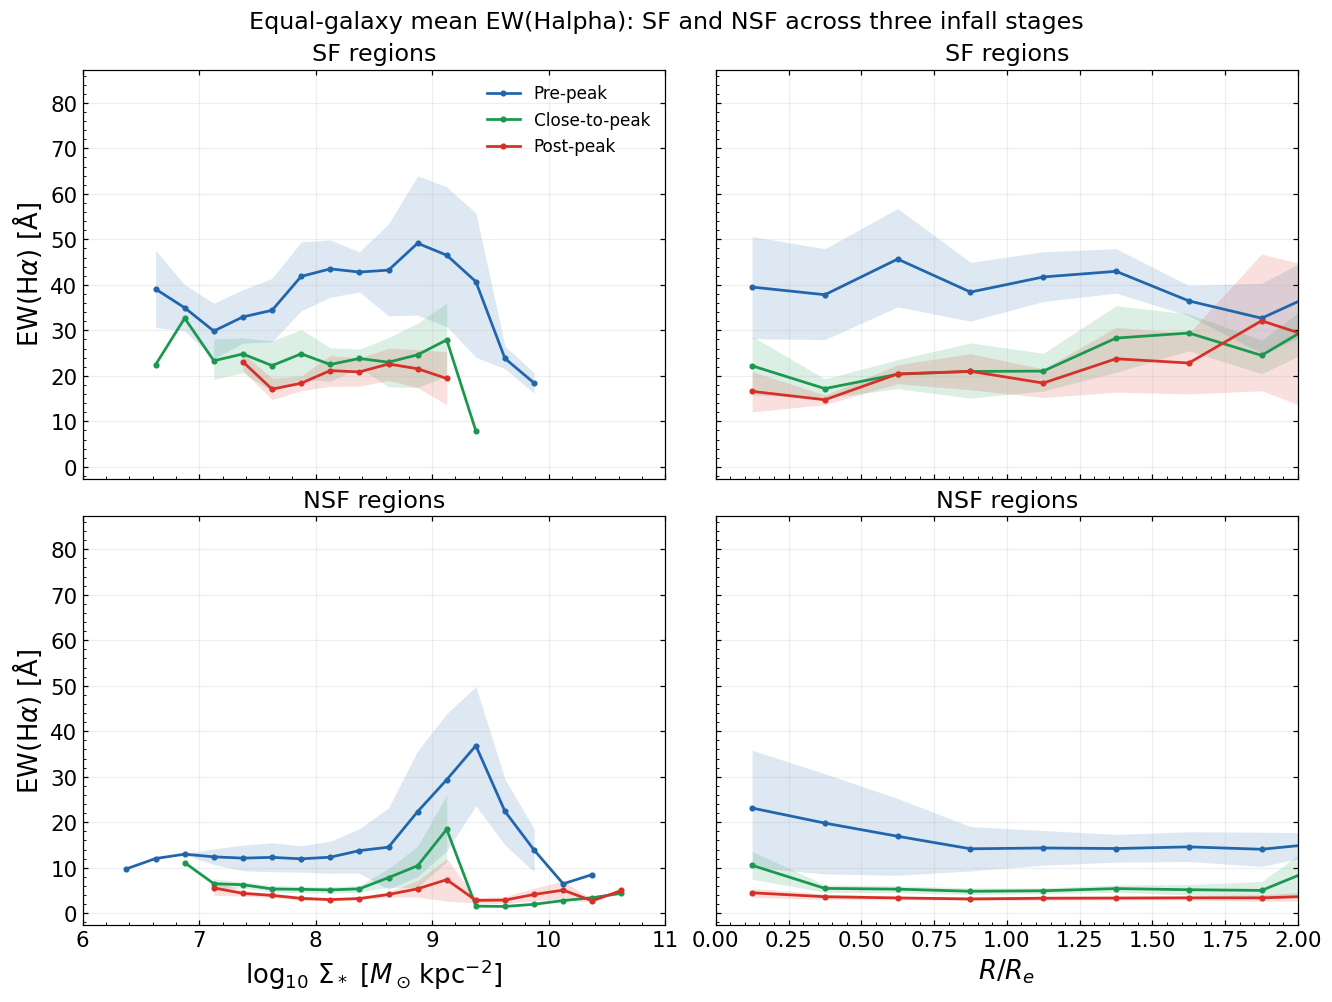

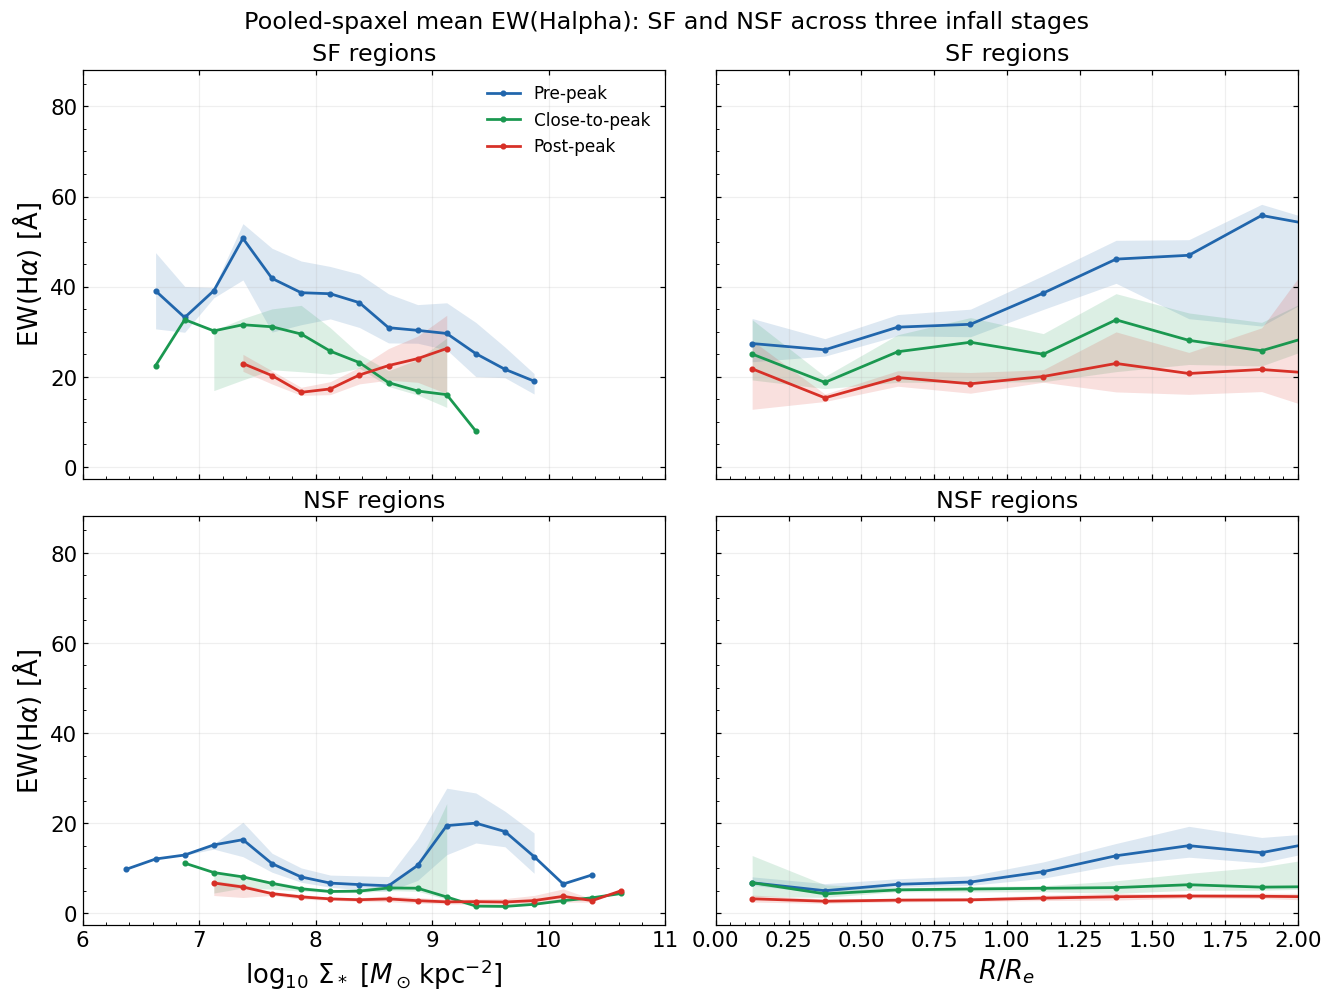

In [6]:
coordinate_labels = {
    'log_sigma_star': r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re': r'$R/R_e$',
}
for branch in ('equal_galaxy', 'pooled_spaxel'):
    fig, axes = plt.subplots(len(CATEGORIES), 2, figsize=(12, 9), sharex='col', sharey=True, layout='constrained')
    for row, category in enumerate(CATEGORIES):
        for col, variable in enumerate(('log_sigma_star', 'radius_re')):
            ax = axes[row, col]
            no_support = []
            for stage in (1, 2, 3):
                p = ewha_profiles.loc[ewha_profiles.branch.eq(branch) & ewha_profiles.stage.eq(stage)
                    & ewha_profiles.category.eq(category) & ewha_profiles.variable.eq(variable)].sort_values('center')
                ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                        lw=1.8, label=STAGE_LABELS[stage])
                ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float), p.hi.to_numpy(float),
                                color=STAGE_COLORS[stage], alpha=0.15, linewidth=0)
                xmin, xmax = PROFILE_X_LIMITS[variable]
                if not p.loc[p.center.between(xmin, xmax), 'N_gal_support'].gt(0).any():
                    no_support.append(STAGE_LABELS[stage])
            if no_support:
                ax.text(0.03, 0.03, 'No supported bins: ' + ', '.join(no_support),
                        transform=ax.transAxes, va='bottom', fontsize=9, color='0.35')
            ax.set_title(category + ' regions')
            ax.set_xlim(PROFILE_X_LIMITS[variable])
            ax.tick_params(top=True, right=True)
            ax.minorticks_on()
            ax.grid(alpha=0.2)
            if row == len(CATEGORIES) - 1:
                ax.set_xlabel(coordinate_labels[variable])
        axes[row, 0].set_ylabel(r'$\mathrm{EW}(\mathrm{H}\alpha)$ [$\mathrm{\AA}$]')
    axes[0, 0].legend(frameon=False)
    label = 'Equal-galaxy mean EW(Halpha)' if branch == 'equal_galaxy' else 'Pooled-spaxel mean EW(Halpha)'
    fig.suptitle(label + ': SF and NSF across three infall stages')
    save_figure(fig, 'EWHa_SF_NSF_by_stage_' + branch)
    plt.show()
    plt.close(fig)

## EW(Halpha) distributions

Show the equal-galaxy pair first, then the pooled-spaxel pair. Within each pair,
show all selected EW(Halpha) values followed by inner R/Re<1 (filled, solid) and
outer R/Re>=1 (open, dashed) contributions. The full available radius range
is retained.

Use 1 Angstrom bins from 0 to 300 Angstrom, with a linear x axis displayed
from 0 to 50 Angstrom. All finite positive EW(Halpha) values remain selected, including values
outside the histogram grid or display. Report tail counts without clipping
or accumulating them into edge bins. The y axis is log10 probability per
1 Angstrom bin, not probability density per unit EW. The profile-only
50/20-spaxel support thresholds do not filter distributions.

Pooled-spaxel probabilities divide bin counts by the full selected category
count in the stage. Equal-galaxy probabilities first divide each product's
histogram by its full selected category count, then average with equal product
weights. Products with zero selected spaxels are excluded from this mean;
eligible products contribute zero in empty EW bins. Both inner and outer
curves use the same full-category denominator as the all-radius curve, so their
linear probabilities add to the all-radius curve for either estimator.

Bootstrap 10,000 whole products within each stage, sharing multiplicities across
categories, radial samples and estimators, and recompute normalization each draw.
Vertical bars show 16th-84th percentiles only where at least two products have
nonzero bin counts. Single-product bins retain central points; zero-count bins
have no logarithmic point. Bounds at zero are marked at the plotting floor with
a downward tick. These are product-sampling uncertainties, with no propagation
of individual EW(Halpha) errors. NGC4567_8 remains one bootstrap unit.


In [7]:
def normalized_histogram_bootstrap(histograms, totals, multiplicities, branch='pooled_spaxel'):
    """Bin fractions with pooled-spaxel or equal-product central and bootstrap weights."""
    histograms = np.asarray(histograms, dtype=float)
    totals = np.asarray(totals, dtype=float)
    assert histograms.ndim == 2 and histograms.shape[0] == len(totals)
    assert np.all(histograms >= 0) and np.all(totals >= 0)
    assert np.all(histograms.sum(axis=1) <= totals)
    if branch == 'equal_galaxy':
        eligible = totals > 0
        values = np.divide(histograms, totals[:, None], out=np.zeros_like(histograms),
                           where=totals[:, None] > 0)
        weights = eligible.astype(float)
    elif branch == 'pooled_spaxel':
        values, weights = histograms, totals
    else:
        raise ValueError(f'Unknown distribution estimator: {branch}')
    central = values.sum(axis=0) / weights.sum() if weights.sum() else np.full(histograms.shape[1], np.nan)
    # Direct sums avoid spurious floating-point warnings from the local matmul backend.
    boot_denominator = np.einsum('bg,g->b', multiplicities, weights, optimize=False)
    boot_numerator = np.einsum('bg,gj->bj', multiplicities, values, optimize=False)
    boot = np.divide(boot_numerator, boot_denominator[:, None],
        out=np.full((len(multiplicities), histograms.shape[1]), np.nan), where=boot_denominator[:, None] > 0)
    finite_draws = boot_denominator > 0
    assert np.isfinite(boot[finite_draws]).all()
    assert np.all((boot[finite_draws] >= 0) & (boot[finite_draws] <= 1 + 1e-12))
    return central, boot, finite_draws

distribution_rows, histogram_qc_rows = [], []
for stage in (1, 2, 3):
    ids = counts.loc[counts.stage.eq(stage), 'galaxy'].sort_values().to_numpy()
    g = len(ids)
    rng = np.random.default_rng(RANDOM_SEED + 23_000_000 + stage)
    multiplicities = (rng.multinomial(g, np.full(g, 1 / g), size=N_BOOTSTRAP)
                      if g else np.empty((N_BOOTSTRAP, 0), dtype=int))
    for category in CATEGORIES:
        region_probabilities = {branch: {} for branch in ('equal_galaxy', 'pooled_spaxel')}
        for region in ('all', 'inner', 'outer'):
            panel = ewha_histograms_by_galaxy.loc[
                ewha_histograms_by_galaxy.stage.eq(stage)
                & ewha_histograms_by_galaxy.category.eq(category)
                & ewha_histograms_by_galaxy.region.eq(region)
            ].set_index('galaxy').reindex(ids)
            assert panel.N_total.notna().all()
            histograms = np.stack(panel['hist'].to_list()) if g else np.empty((0, len(EWHA_HIST_EDGES) - 1))
            totals = panel.N_total.to_numpy(float)
            support = (histograms > 0).sum(axis=0)
            for branch in ('equal_galaxy', 'pooled_spaxel'):
                central, boot, valid_draws = normalized_histogram_bootstrap(histograms, totals, multiplicities, branch)
                region_probabilities[branch][region] = central
                bounds = np.percentile(boot[valid_draws], [16, 84], axis=0) if valid_draws.any() else np.full((2, histograms.shape[1]), np.nan)
                bounds[:, support < 2] = np.nan
                for j, (lo, hi) in enumerate(zip(EWHA_HIST_EDGES[:-1], EWHA_HIST_EDGES[1:])):
                    distribution_rows.append(dict(branch=branch, stage=stage, category=category, region=region,
                        left=lo, right=hi, center=(lo + hi) / 2, N_bin=int(histograms[:, j].sum()),
                        N_total=int(totals.sum()), N_products_normalized=int((totals > 0).sum()),
                        N_products_in_bin=int(support[j]), N_finite_draws=int(valid_draws.sum()),
                        probability=central[j], lo=bounds[0, j], hi=bounds[1, j]))
            histogram_qc_rows.append(dict(stage=STAGE_LABELS[stage], category=category, region=region,
                N_total=int(totals.sum()), N_products_normalized=int((totals > 0).sum()),
                N_products_excluded_empty=int((totals == 0).sum()), N_region=int(panel.N_region.sum()),
                N_in_grid=int(histograms.sum()), N_below_grid=int(panel.N_below_grid.sum()),
                N_above_grid=int(panel.N_above_grid.sum()),
                N_outside_display_all_radii=int(panel.N_outside_display.sum()),
                N_products_with_region=int(panel.N_region.gt(0).sum())))
        for branch in ('equal_galaxy', 'pooled_spaxel'):
            probabilities = region_probabilities[branch]
            if np.isfinite(probabilities['all']).any():
                assert np.allclose(probabilities['all'], probabilities['inner'] + probabilities['outer'])

ewha_distributions = pd.DataFrame(distribution_rows)
histogram_qc = pd.DataFrame(histogram_qc_rows)
assert len(ewha_distributions) == 2 * 3 * len(CATEGORIES) * 3 * (len(EWHA_HIST_EDGES) - 1)
assert not ewha_distributions.duplicated(['branch', 'stage', 'category', 'region', 'left']).any()
assert (histogram_qc.N_region == histogram_qc.N_in_grid + histogram_qc.N_below_grid + histogram_qc.N_above_grid).all()
assert ewha_distributions.loc[ewha_distributions.N_products_in_bin.lt(2), ['lo', 'hi']].isna().all().all()
display(histogram_qc)
display(ewha_distributions.groupby(['branch', 'stage', 'category', 'region'])[['N_bin', 'probability']].sum())
print('Both estimators: normalization, radial partition, histogram tails and product support checks passed.')

,stage,category,region,N_total,N_products_normalized,N_products_excluded_empty,N_region,N_in_grid,N_below_grid,N_above_grid,N_outside_display_all_radii,N_products_with_region
0,Pre-peak,SF,all,1420915,8,0,1420915,1412732,0,8183,303730,8
1,Pre-peak,SF,inner,1420915,8,0,733158,732139,0,1019,303730,8
2,Pre-peak,SF,outer,1420915,8,0,687757,680593,0,7164,303730,8
3,Pre-peak,NSF,all,929104,8,0,929104,929084,0,20,13324,8
4,Pre-peak,NSF,inner,929104,8,0,599708,599708,0,0,13324,8
5,Pre-peak,NSF,outer,929104,8,0,329396,329376,0,20,13324,8
6,Close-to-peak,SF,all,720842,5,0,720842,718991,0,1851,81805,5
7,Close-to-peak,SF,inner,720842,5,0,272068,271811,0,257,81805,5
8,Close-to-peak,SF,outer,720842,5,0,448774,447180,0,1594,81805,4
9,Close-to-peak,NSF,all,488865,5,0,488865,488865,0,0,485,5


N_bin  probability
branch        stage category region                      
equal_galaxy  1     NSF      all      929084     0.999973
                             inner    599708     0.542814
                             outer    329376     0.457159
                    SF       all     1412732     0.995518
                             inner    732139     0.520420
                             outer    680593     0.475098
              2     NSF      all      488865     1.000000
                             inner    181763     0.489004
                             outer    307102     0.510996
                    SF       all      718991     0.998610
                             inner    271811     0.629994
                             outer    447180     0.368616
              3     NSF      all      815887     1.000000
                             inner    505732     0.686613
                             outer    310155     0.313387
                    SF       all      222392     0.999732
                             inner    151635     0.673919
                             outer     70757     0.325814
pooled_spaxel 1     NSF      all      929084     0.999978
                             inner    599708     0.645469
                             outer    329376     0.354509
                    SF       all     1412732     0.994241
                             inner    732139     0.515259
                             outer    680593     0.478982
              2     NSF      all      488865     1.000000
                             inner    181763     0.371806
                             outer    307102     0.628194
                    SF       all      718991     0.997432
                             inner    271811     0.377074
                             outer    447180     0.620358
              3     NSF      all      815887     1.000000
                             inner    505732     0.619855
                             outer    310155     0.380145
                    SF       all      222392     0.999843
                             inner    151635     0.681729
                             outer     70757     0.318113

Both estimators: normalization, radial partition, histogram tails and product support checks passed.


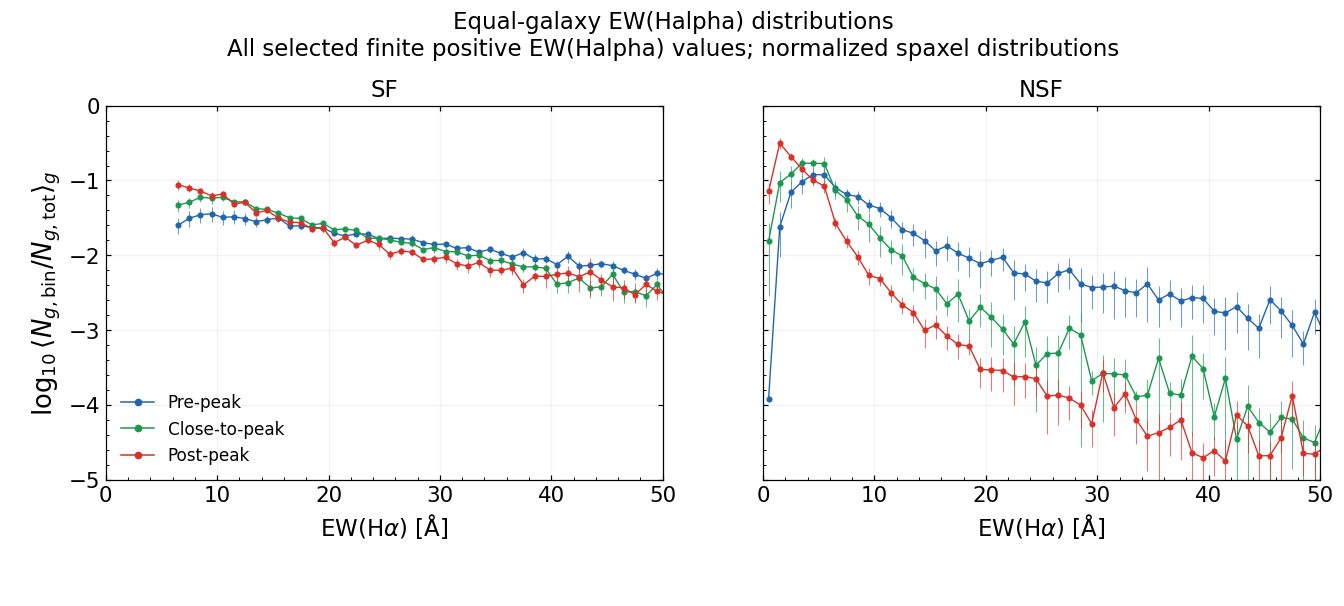

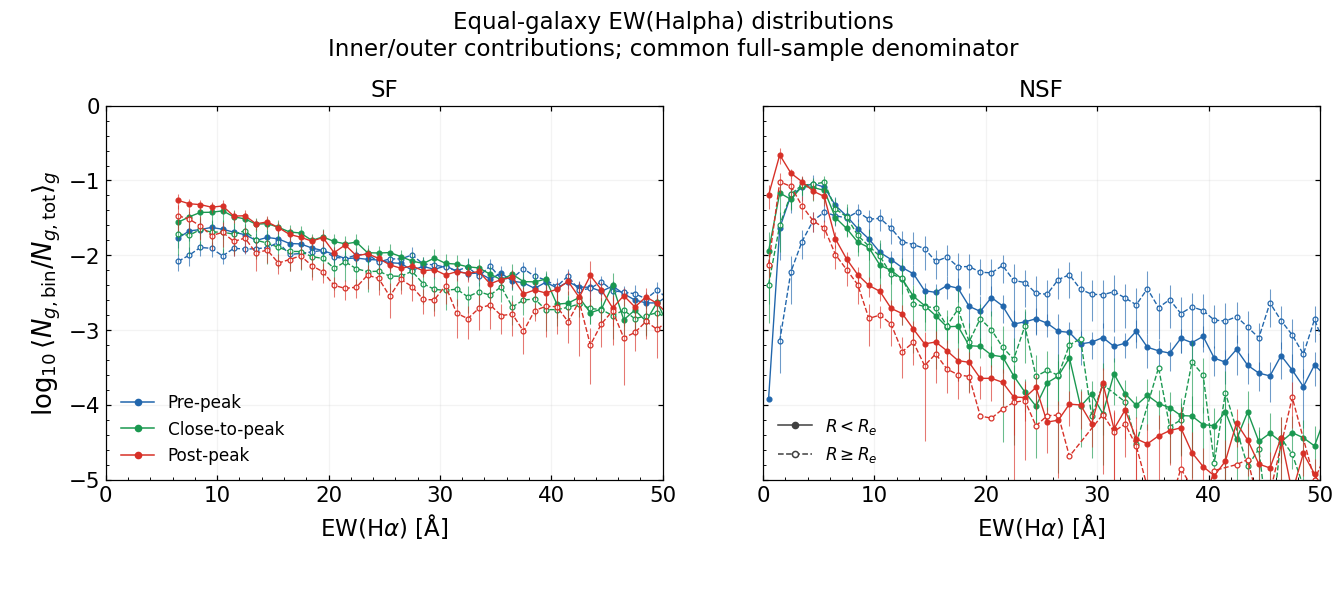

In [8]:
from matplotlib.lines import Line2D

def draw_ewha_distribution(ax, panel, color, filled, linestyle, label=None):
    positive = panel.loc[panel.probability.gt(0)].sort_values('center')
    if positive.empty:
        return
    x = positive.center.to_numpy(float)
    y = np.log10(positive.probability.to_numpy(float))
    ax.plot(x, y, color=color, marker='o', ms=3.2, lw=0.9, ls=linestyle,
            markerfacecolor=color if filled else 'white', markeredgewidth=0.8, label=label)
    band = positive.loc[positive.N_products_in_bin.ge(2) & positive.lo.notna() & positive.hi.gt(0)]
    if len(band):
        floor = 10.0 ** EWHA_HIST_LOG_LIMITS[0]
        lower = np.log10(np.maximum(band.lo.to_numpy(float), floor))
        upper = np.log10(np.maximum(band.hi.to_numpy(float), floor))
        ax.vlines(band.center, lower, upper, color=color, lw=0.7, alpha=0.65)
        zero_bound = band.lo.le(0)
        ax.plot(band.loc[zero_bound, 'center'], np.full(int(zero_bound.sum()), EWHA_HIST_LOG_LIMITS[0]),
                marker='v', ms=3, linestyle='none', color=color, clip_on=False)



def plot_ewha_distributions(branch):
    for radial_split in (False, True):
        fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(12, 5.4), sharex=True, sharey=True)
        fig.subplots_adjust(left=0.07, right=0.99, bottom=0.19, top=0.82, wspace=0.18)
        for ax, category in zip(axes, CATEGORIES):
            for stage in (1, 2, 3):
                regions = ('inner', 'outer') if radial_split else ('all',)
                for region in regions:
                    panel = ewha_distributions.loc[ewha_distributions.branch.eq(branch) & ewha_distributions.stage.eq(stage)
                        & ewha_distributions.category.eq(category) & ewha_distributions.region.eq(region)]
                    draw_ewha_distribution(ax, panel, STAGE_COLORS[stage], filled=region != 'outer',
                        linestyle='--' if region == 'outer' else '-', label=STAGE_LABELS[stage] if region != 'outer' else None)
            ax.set_title(category, fontsize=15)
            ax.set_xlim(EWHA_HIST_X_LIMITS)
            ax.set_ylim(EWHA_HIST_LOG_LIMITS)
            ax.set_xlabel(r'$\mathrm{EW}(\mathrm{H}\alpha)$ [$\mathrm{\AA}$]', fontsize=15)
            ax.tick_params(top=True, right=True)
            ax.minorticks_on()
            ax.grid(alpha=0.15)
        ylabel = (r'$\log_{10}\langle N_{g,\rm bin}/N_{g,\rm tot}\rangle_g$'
                  if branch == 'equal_galaxy' else r'$\log_{10}(N_{\rm bin}/N_{\rm tot})$')
        axes[0].set_ylabel(ylabel)
        stage_handles = [Line2D([], [], color=STAGE_COLORS[s], marker='o', ms=4, lw=1, label=STAGE_LABELS[s]) for s in (1, 2, 3)]
        axes[0].legend(handles=stage_handles, frameon=False, loc='lower left')
        if radial_split:
            radius_handles = [Line2D([], [], color='0.25', marker='o', ms=4, lw=1, ls='-', label=r'$R<R_e$'),
                Line2D([], [], color='0.25', marker='o', markerfacecolor='white', ms=4, lw=1, ls='--', label=r'$R\geq R_e$')]
            axes[-1].legend(handles=radius_handles, frameon=False, loc='lower left')
        title = 'Inner/outer contributions; common full-sample denominator' if radial_split else 'All selected finite positive EW(Halpha) values; normalized spaxel distributions'
        estimator = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
        fig.suptitle(estimator + ' EW(Halpha) distributions\n' + title, fontsize=15)
        save_figure(fig, 'EWHa_distribution_by_stage_' + branch + '_' + ('inner_outer' if radial_split else 'all_radii'))
        plt.show()
        plt.close(fig)

# Equal-galaxy pair comes before the pooled-spaxel pair.
plot_ewha_distributions('equal_galaxy')

## Pooled-spaxel distributions
Retain the original pooled-spaxel estimator and whole-product bootstrap for comparison.


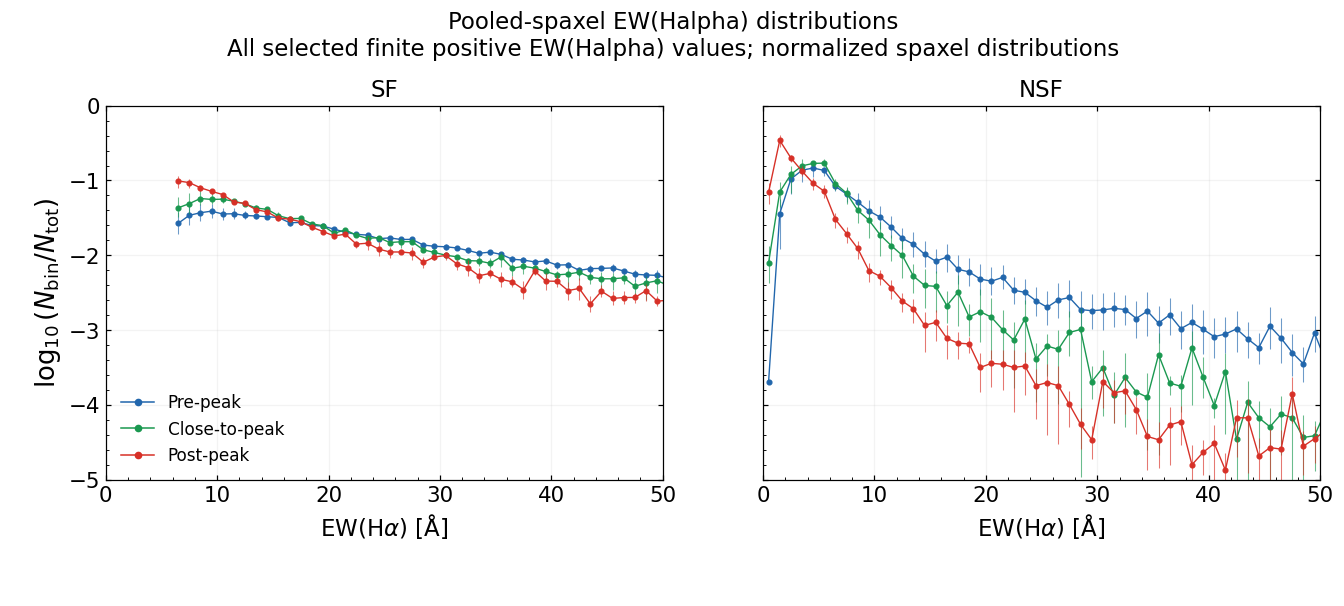

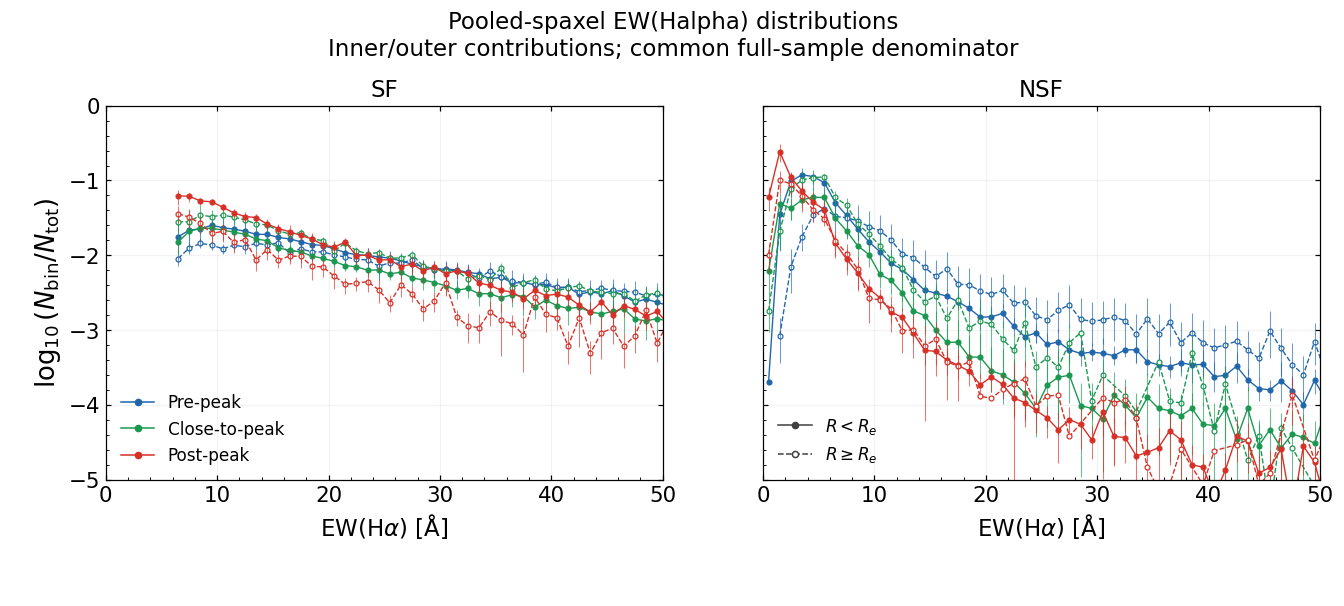

In [9]:
plot_ewha_distributions('pooled_spaxel')

## Distributions within stellar surface-density and radial bins

Normalize **each spatial bin separately**, as requested. Mass and radius are
two separate splits, not a joint grid of mass-radius selections. Mass means
local log10 stellar surface density in Msun/kpc^2, not total galaxy mass.

- Local log Sigma_star: <7.5; 7.5<=x<8.5; 8.5<=x<=9.5; >9.5.
- Radius R/Re: 0<=x<0.5; 0.5<=x<1; 1<=x<=1.5; >1.5.

Within each stage/catalogue/spatial bin, the pooled-spaxel distribution is
sum_g(N_gj)/sum_g(N_g,bin). The equal-galaxy distribution is the mean of
N_gj/N_g,bin over products with at least one selected finite positive EW(Halpha) in that
spatial bin. Products empty in that bin are excluded from the mean; an eligible
product with zero counts in a particular EW(Halpha) bin contributes zero there.
Consequently the galaxy set can differ between spatial bins. Report those
counts explicitly. Full bin denominators include EW(Halpha) tails beyond the
histogram grid or display range, just as for the earlier distributions.

Keep all existing selection cuts and the same 10,000 whole-product bootstrap
draws within each stage, shared across spatial bins, catalogues and estimators.
Recompute each spatial-bin normalization per draw. Use 16th-84th percentiles;
retain the earlier rule of requiring two contributing products in a EW(Halpha) bin
for error bars. No profile-only 50/20-spaxel support gate is introduced here.
NGC4567_8 remains one product/bootstrap unit.

Four new 2x4 figures follow: equal-galaxy mass and radius splits first, then
pooled-spaxel mass and radius splits. Rows are SF and NSF; columns are
the four spatial bins; curves are the three infall stages. EW(Halpha) axes increase from 0 to 50 Angstrom. These conditional distributions compare shapes; the four
separately normalized curves are not additive contributions to the parent.

In [10]:
# Verify that the four spatial bins account for every selected parent spaxel.
for keys, panel in stratified_histograms_by_galaxy.groupby(['galaxy', 'category', 'variable']):
    assert len(panel) == 4 and panel.N_parent.nunique() == 1
    assert panel.N_total.sum() == panel.N_parent.iloc[0]

stratified_rows, stratified_qc_rows = [], []
for stage in (1, 2, 3):
    ids = counts.loc[counts.stage.eq(stage), 'galaxy'].sort_values().to_numpy()
    g = len(ids)
    rng = np.random.default_rng(RANDOM_SEED + 23_000_000 + stage)
    multiplicities = (rng.multinomial(g, np.full(g, 1 / g), size=N_BOOTSTRAP)
                      if g else np.empty((N_BOOTSTRAP, 0), dtype=int))
    for category in CATEGORIES:
        for variable in STRATUM_LABELS:
            for stratum in range(4):
                panel = stratified_histograms_by_galaxy.loc[
                    stratified_histograms_by_galaxy.stage.eq(stage)
                    & stratified_histograms_by_galaxy.category.eq(category)
                    & stratified_histograms_by_galaxy.variable.eq(variable)
                    & stratified_histograms_by_galaxy.stratum.eq(stratum)
                ].set_index('galaxy').reindex(ids)
                assert panel.N_total.notna().all()
                hist = np.stack(panel['hist'].to_list()) if g else np.empty((0, len(EWHA_HIST_EDGES) - 1))
                totals = panel.N_total.to_numpy(float)
                support = (hist > 0).sum(axis=0)
                eligible = totals > 0
                for branch in ('equal_galaxy', 'pooled_spaxel'):
                    central, boot, valid_draws = normalized_histogram_bootstrap(hist, totals, multiplicities, branch)
                    bounds = (np.percentile(boot[valid_draws], [16, 84], axis=0) if valid_draws.any()
                              else np.full((2, hist.shape[1]), np.nan))
                    bounds[:, support < 2] = np.nan
                    if eligible.any():
                        assert np.isfinite(central).all() and np.all(central >= 0)
                        expected = ((hist[eligible] / totals[eligible, None]).mean(axis=0)
                                    if branch == 'equal_galaxy' else hist.sum(axis=0) / totals.sum())
                        assert np.allclose(central, expected)
                        tail = panel.N_below_grid.to_numpy(float) + panel.N_above_grid.to_numpy(float)
                        missing = ((tail[eligible] / totals[eligible]).mean() if branch == 'equal_galaxy'
                                   else tail.sum() / totals.sum())
                        assert np.isclose(central.sum() + missing, 1.0)
                    else:
                        assert np.isnan(central).all() and not valid_draws.any()
                    for j, (lo, hi) in enumerate(zip(EWHA_HIST_EDGES[:-1], EWHA_HIST_EDGES[1:])):
                        stratified_rows.append(dict(branch=branch, stage=stage, category=category,
                            variable=variable, stratum=stratum, left=lo, right=hi, center=(lo + hi) / 2,
                            N_bin=int(hist[:, j].sum()), N_total=int(totals.sum()),
                            N_products_normalized=int(eligible.sum()), N_products_in_bin=int(support[j]),
                            N_finite_draws=int(valid_draws.sum()), probability=central[j], lo=bounds[0, j], hi=bounds[1, j]))
                stratified_qc_rows.append(dict(stage=STAGE_LABELS[stage], category=category,
                    variable=variable, stratum=stratum, label=STRATUM_LABELS[variable][stratum],
                    N_total=int(totals.sum()), N_products_normalized=int(eligible.sum()),
                    N_products_excluded_empty=int((~eligible).sum()), N_in_grid=int(hist.sum()),
                    N_below_grid=int(panel.N_below_grid.sum()), N_above_grid=int(panel.N_above_grid.sum()),
                    N_outside_display=int(panel.N_outside_display.sum())))

stratified_ewha_distributions = pd.DataFrame(stratified_rows)
stratified_histogram_qc = pd.DataFrame(stratified_qc_rows)
assert len(stratified_ewha_distributions) == 2 * 3 * len(CATEGORIES) * 2 * 4 * (len(EWHA_HIST_EDGES) - 1)
assert not stratified_ewha_distributions.duplicated(['branch', 'stage', 'category', 'variable', 'stratum', 'left']).any()
assert (stratified_histogram_qc.N_total == stratified_histogram_qc.N_in_grid
        + stratified_histogram_qc.N_below_grid + stratified_histogram_qc.N_above_grid).all()
assert stratified_ewha_distributions.loc[stratified_ewha_distributions.N_products_in_bin.lt(2), ['lo', 'hi']].isna().all().all()
display(stratified_histogram_qc)
print('Spatial partitions, separate-bin normalization, both estimators, ewha tails and empty strata verified.')

,stage,category,variable,stratum,label,N_total,N_products_normalized,N_products_excluded_empty,N_in_grid,N_below_grid,N_above_grid,N_outside_display
0,Pre-peak,SF,log_sigma_star,0,$\log\Sigma_*<7.5$,129240,7,1,128568,0,672,39634
1,Pre-peak,SF,log_sigma_star,1,$7.5\leq\log\Sigma_*<8.5$,1150485,8,0,1143186,0,7299,244407
2,Pre-peak,SF,log_sigma_star,2,$8.5\leq\log\Sigma_*\leq9.5$,140215,8,0,140003,0,212,19674
3,Pre-peak,SF,log_sigma_star,3,$\log\Sigma_*>9.5$,975,6,2,975,0,0,15
4,Pre-peak,SF,radius_re,0,$0\leq R/R_e<0.5$,170009,8,0,169985,0,24,18482
5,Pre-peak,SF,radius_re,1,$0.5\leq R/R_e<1$,563149,8,0,562154,0,995,87251
6,Pre-peak,SF,radius_re,2,$1\leq R/R_e\leq1.5$,398315,8,0,396045,0,2270,99282
7,Pre-peak,SF,radius_re,3,$R/R_e>1.5$,289442,7,1,284548,0,4894,98715
8,Pre-peak,NSF,log_sigma_star,0,$\log\Sigma_*<7.5$,83995,7,1,83995,0,0,2486
9,Pre-peak,NSF,log_sigma_star,1,$7.5\leq\log\Sigma_*<8.5$,745024,8,0,745004,0,20,8261


Spatial partitions, separate-bin normalization, both estimators, ewha tails and empty strata verified.


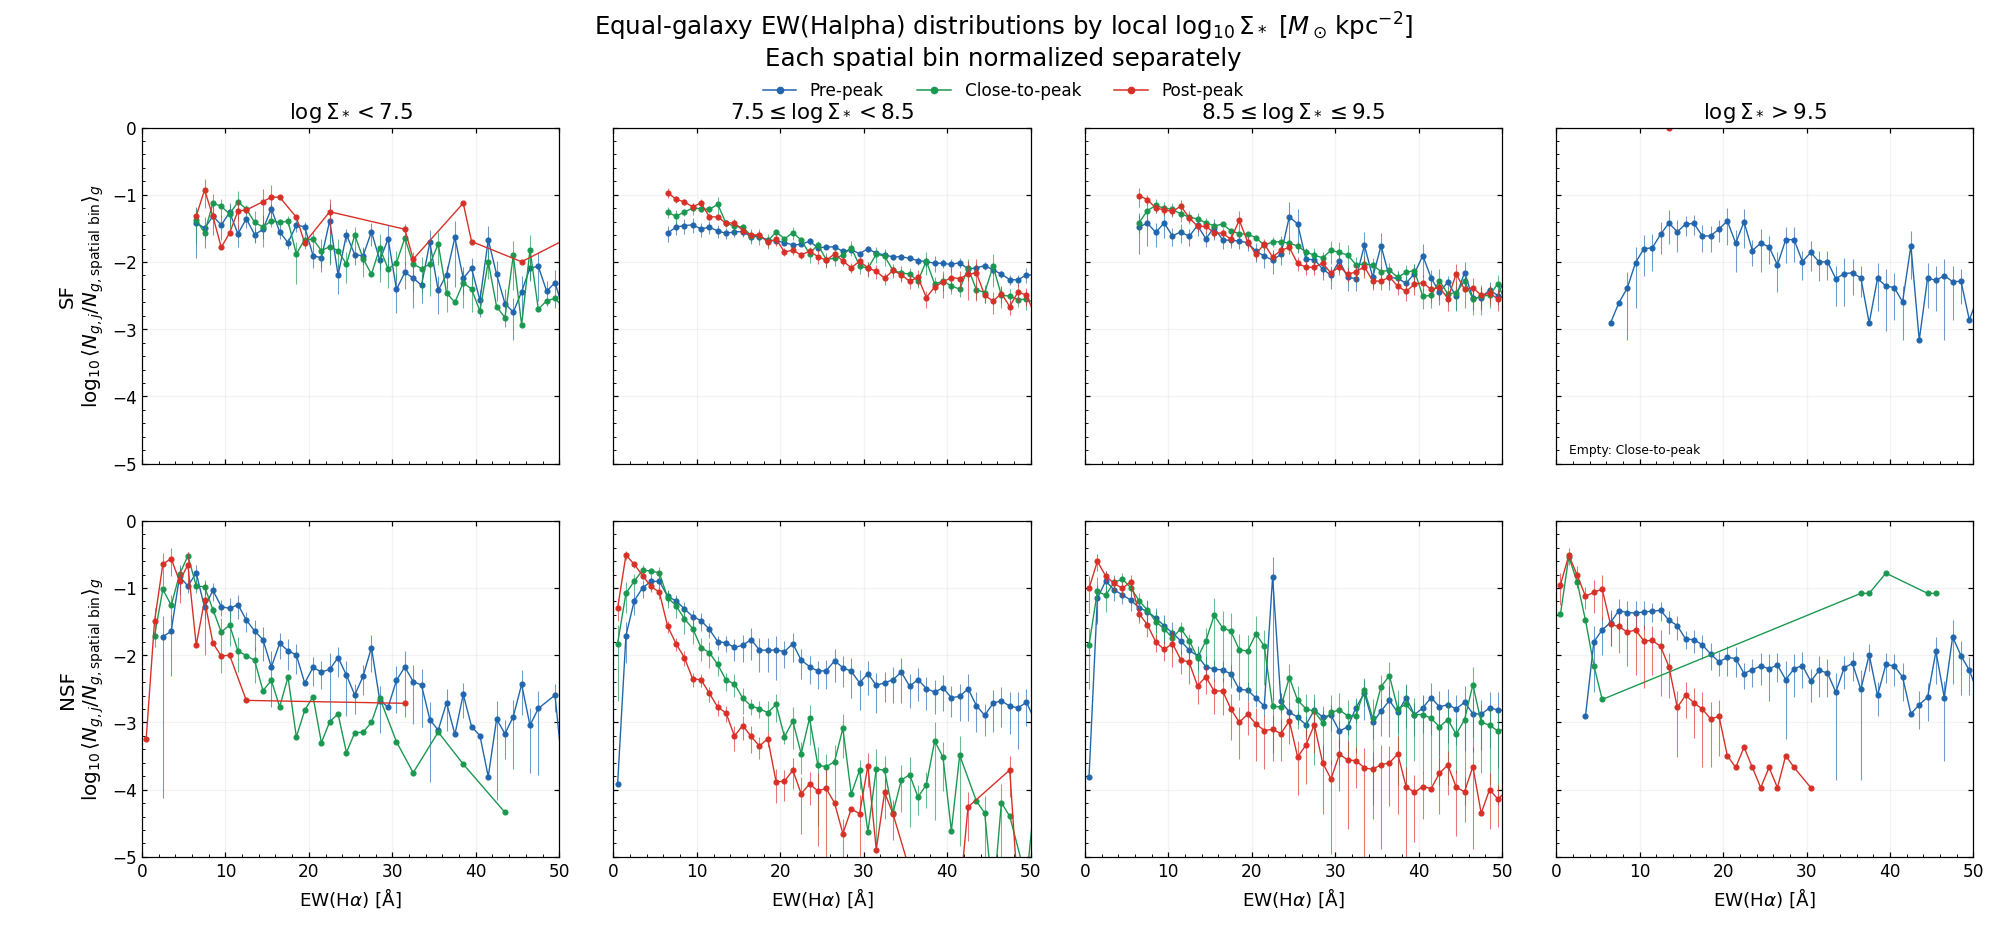

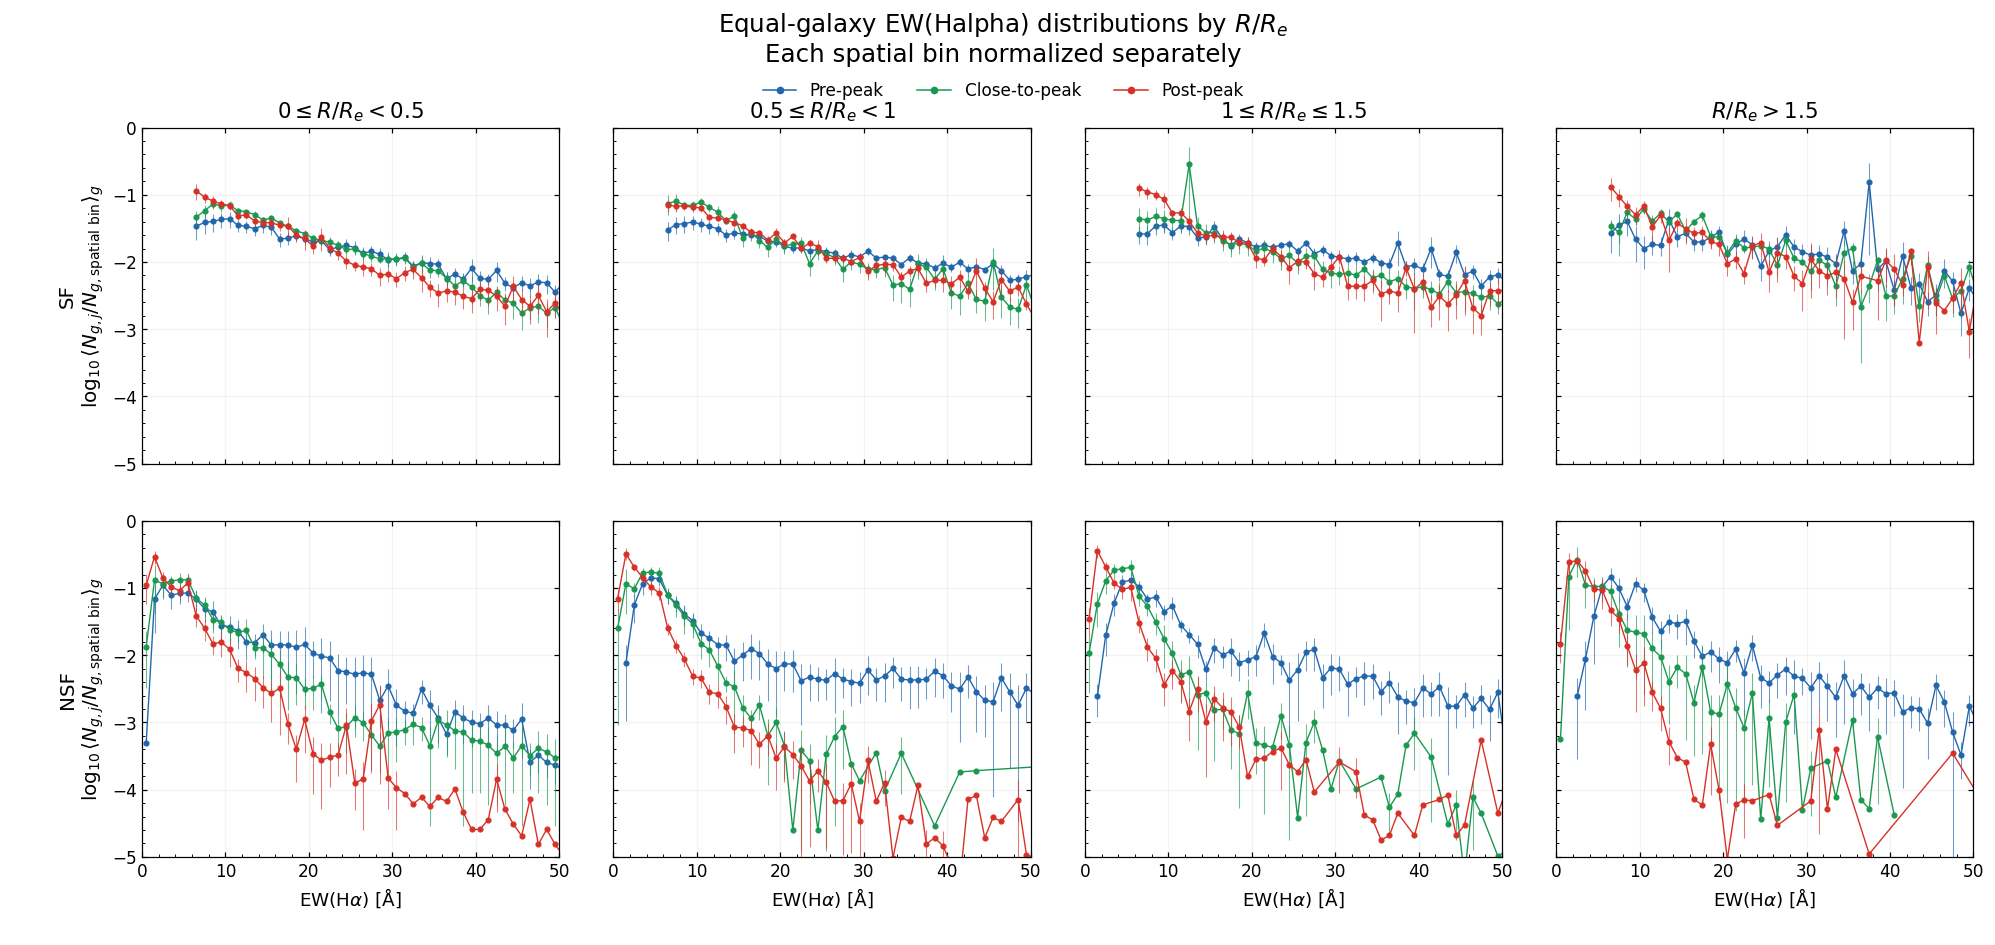

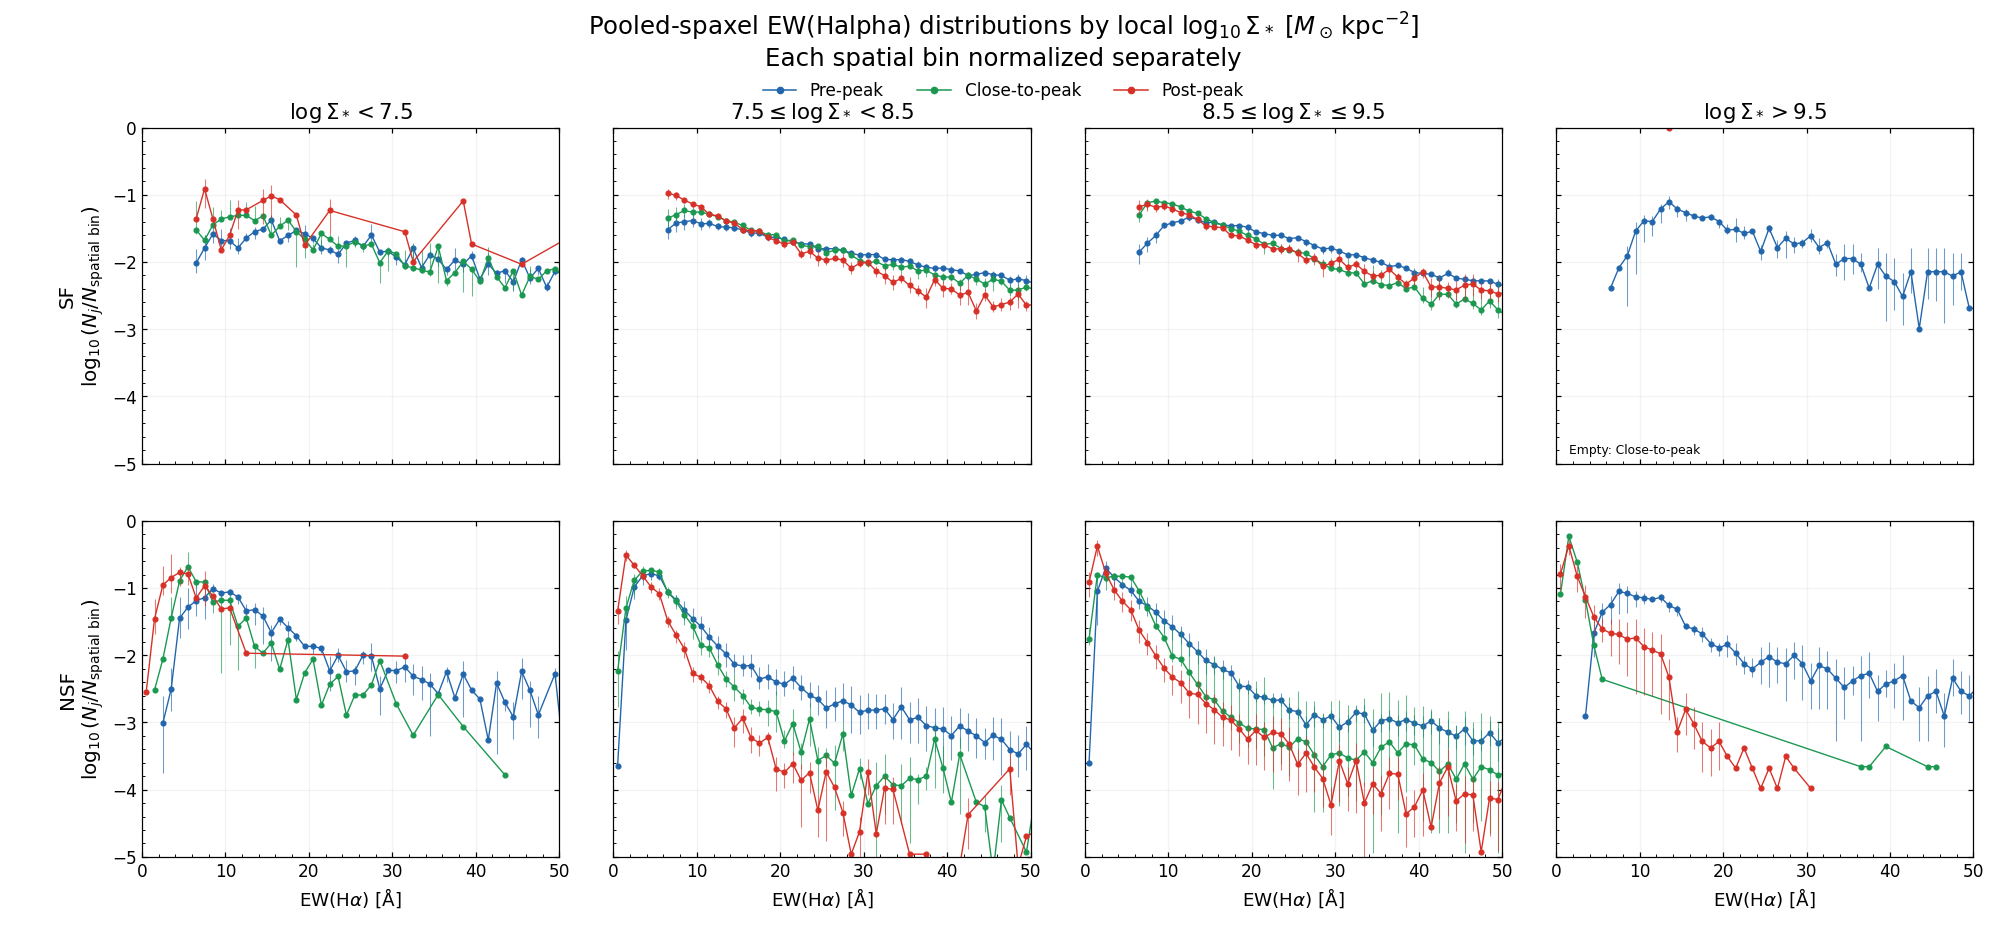

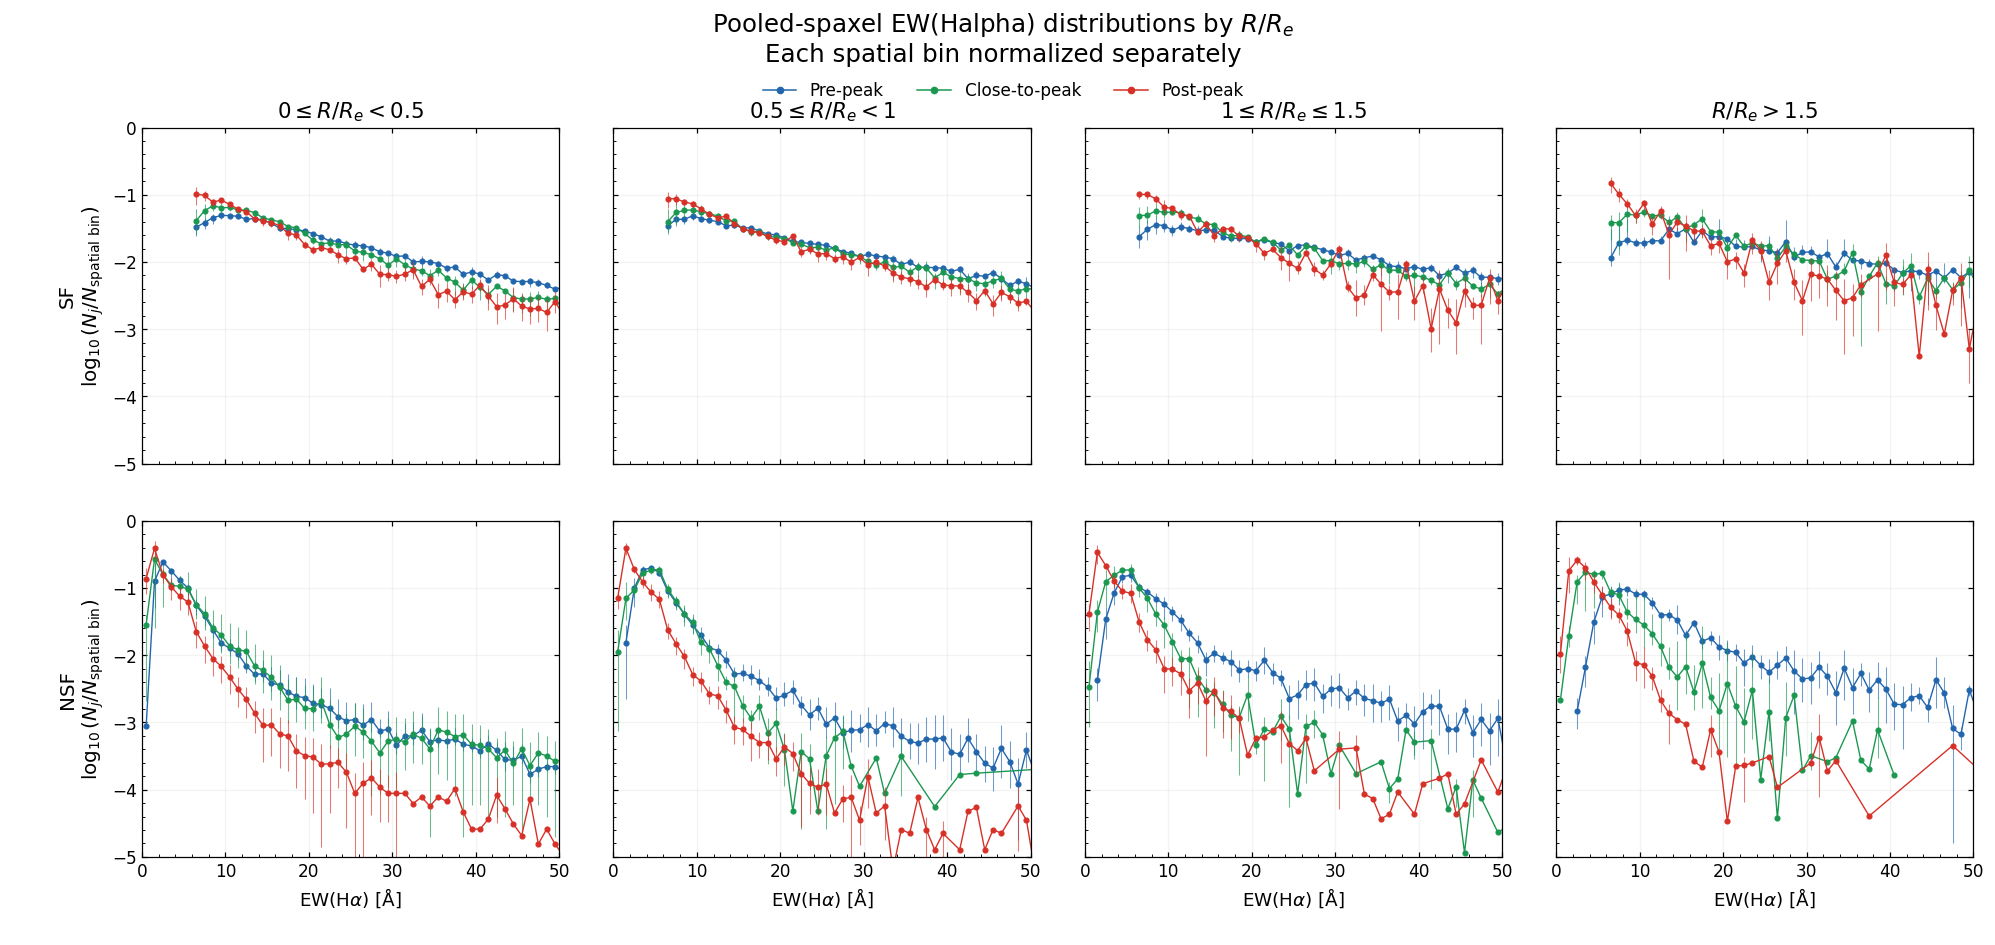

In [11]:
def plot_stratified_ewha_distributions(branch, variable):
    fig, axes = plt.subplots(len(CATEGORIES), 4, figsize=(18, 8.5), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.065, right=0.99, bottom=0.08, top=0.86, wspace=0.13, hspace=0.17)
    for row, category in enumerate(CATEGORIES):
        for stratum in range(4):
            ax = axes[row, stratum]
            no_sample = []
            for stage in (1, 2, 3):
                panel = stratified_ewha_distributions.loc[
                    stratified_ewha_distributions.branch.eq(branch)
                    & stratified_ewha_distributions.variable.eq(variable)
                    & stratified_ewha_distributions.stratum.eq(stratum)
                    & stratified_ewha_distributions.category.eq(category)
                    & stratified_ewha_distributions.stage.eq(stage)]
                draw_ewha_distribution(ax, panel, STAGE_COLORS[stage], filled=True, linestyle='-')
                if not panel.N_total.gt(0).any():
                    no_sample.append(STAGE_LABELS[stage])
            if no_sample:
                ax.text(0.03, 0.03, 'Empty: ' + ', '.join(no_sample), transform=ax.transAxes, fontsize=8)
            if row == 0:
                ax.set_title(STRATUM_LABELS[variable][stratum], fontsize=14)
            if stratum == 0:
                ax.set_ylabel(category + '\n' + (r'$\log_{10}\langle N_{g,j}/N_{g,\rm spatial\ bin}\rangle_g$'
                    if branch == 'equal_galaxy' else r'$\log_{10}(N_j/N_{\rm spatial\ bin})$'), fontsize=13)
            if row == len(CATEGORIES) - 1:
                ax.set_xlabel(r'$\mathrm{EW}(\mathrm{H}\alpha)$ [$\mathrm{\AA}$]', fontsize=12)
            ax.set_xlim(EWHA_HIST_X_LIMITS)
            ax.set_ylim(EWHA_HIST_LOG_LIMITS)
            ax.tick_params(top=True, right=True, labelsize=11)
            ax.minorticks_on()
            ax.grid(alpha=0.15)
    handles = [Line2D([], [], color=STAGE_COLORS[s], marker='o', ms=4, lw=1, label=STAGE_LABELS[s]) for s in (1, 2, 3)]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.925), ncol=3, frameon=False)
    estimator = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
    split_label = r'local $\log_{10}\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]' if variable == 'log_sigma_star' else r'$R/R_e$'
    fig.suptitle(estimator + ' EW(Halpha) distributions by ' + split_label
                 + '\nEach spatial bin normalized separately', fontsize=16, y=0.985)
    save_figure(fig, 'EWHa_distribution_' + branch + '_by_' + variable)
    plt.show()
    plt.close(fig)

for branch in ('equal_galaxy', 'pooled_spaxel'):
    for variable in ('log_sigma_star', 'radius_re'):
        plot_stratified_ewha_distributions(branch, variable)